In [ ]:
%pip install matplotlib pillow

In [1]:
from pathlib import Path

DATA_DIR = Path("../data/VOCdevkit")

VOC_DIR_07 = DATA_DIR / "VOC2007" 
VOC_DIR_12 = DATA_DIR / "VOC2012"

IMAGE_DIR_07 = VOC_DIR_07 / "JPEGImages"
IMAGE_DIR_12 = VOC_DIR_12 / "JPEGImages"

ANNOTATION_DIR_07 = VOC_DIR_07 / "Annotations"
ANNOTATION_DIR_12 = VOC_DIR_12 / "Annotations"

image_ids_2007 = sorted(
    path.stem for path in ANNOTATION_DIR_07.glob("*.xml")
)

image_ids_2012 = sorted(
    path.stem for path in ANNOTATION_DIR_12.glob("*.xml")
)

In [3]:
import xml.etree.ElementTree as ET

image_id = image_ids_2007[14]  # You can change the index to explore different images

xml_path = ANNOTATION_DIR_07 / f"{image_id}.xml" # Exploration of VOC2007 annotations
root = ET.parse(xml_path).getroot()

for obj in root.findall("object"):
    class_name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    print(class_name, (xmin, ymin, xmax, ymax))

aeroplane (9, 107, 499, 263)
aeroplane (421, 200, 482, 226)
aeroplane (325, 188, 411, 223)


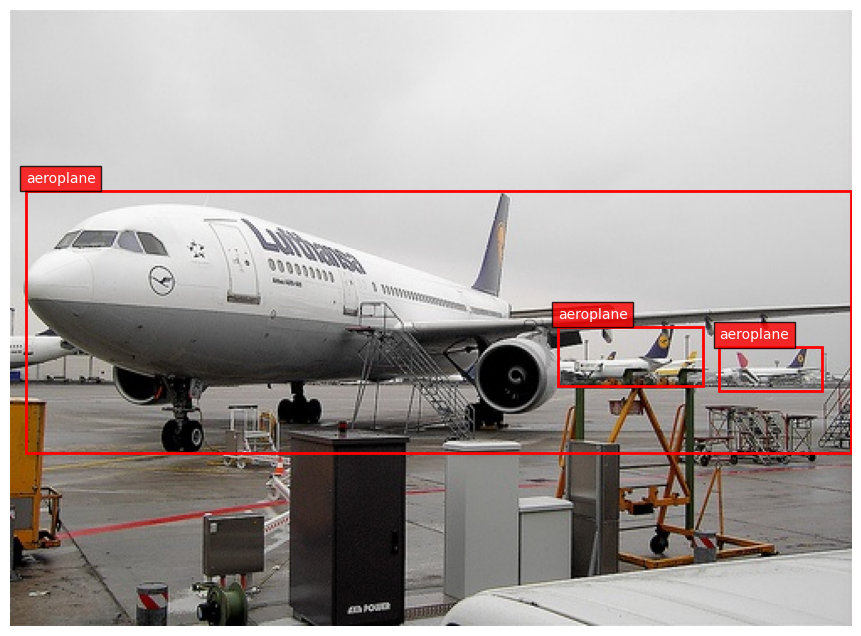

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image_path = IMAGE_DIR_07 / f"{image_id}.jpg"
image = Image.open(image_path).convert("RGB")

fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

for obj in root.findall("object"):
    class_name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none",
    )
    ax.add_patch(rect)

    ax.text(
        xmin,
        max(ymin - 5, 0),
        class_name,
        color="white",
        fontsize=10,
        bbox=dict(facecolor="red", alpha=0.8),
    )

ax.axis("off")
plt.show()

In [6]:
has_errors = False

# Verification of the VOC2007 dataset structure
for image_id in image_ids_2007:
    image_path = IMAGE_DIR_07 / f"{image_id}.jpg"
    xml_path = ANNOTATION_DIR_07 / f"{image_id}.xml"

    if not image_path.exists():
        print(f"Image file missing: {image_path}")
        has_errors = True
    if not xml_path.exists():
        print(f"Annotation file missing: {xml_path}")
        has_errors = True

# Verification of the VOC2012 dataset structure
for image_id in image_ids_2012:
    image_path = IMAGE_DIR_12 / f"{image_id}.jpg"
    xml_path = ANNOTATION_DIR_12 / f"{image_id}.xml"

    if not image_path.exists():
        print(f"Image file missing: {image_path}")
        has_errors = True
    if not xml_path.exists():
        print(f"Annotation file missing: {xml_path}")
        has_errors = True

if not has_errors:
    print("Dataset verification passed: no missing images or annotations.")

Dataset verification passed: no missing images or annotations.
